<a href="https://colab.research.google.com/github/Kurnia010402/Tugas-Machine-Learning/blob/main/Praktikum_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tugas Mechine Learning 13

13.1 Persiapan Library

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

### Persiapan Dataset CIFAR-10 (Subset Terbatas untuk Simulasi)

In [ ]:
import numpy as np

# Load dataset CIFAR-10 bawaan Keras
(x_train_full, y_train_full), (x_test_full, y_test_full) = keras.datasets.cifar10.load_data()

# Mengambil subset kecil: 1000 gambar per kelas untuk train, 200 per kelas untuk validation
def create_subset(x, y, samples_per_class):
    x_sub, y_sub = [], []
    for i in range(10):
        indices = np.where(y == i)[0][:samples_per_class]
        x_sub.append(x[indices])
        y_sub.append(y[indices])
    return np.concatenate(x_sub), np.concatenate(y_sub)

x_train, y_train = create_subset(x_train_full, y_train_full, 1000)
x_val, y_val = create_subset(x_test_full, y_test_full, 200)

# Normalisasi piksel ke rentang [0, 1] untuk CNN dari nol
x_train_scaled = x_train.astype("float32") / 255.0
x_val_scaled = x_val.astype("float32") / 255.0

print(f"Ukuran data training: {x_train.shape}")
print(f"Ukuran data validasi: {x_val.shape}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3845s 23us/step
Ukuran data training: (10000, 32, 32, 3)
Ukuran data validasi: (2000, 32, 32, 3)


### Praktikum 1: Membangun CNN Sederhana dari Nol (Scratch)

Kita akan mendesain arsitektur CNN sederhana dengan input layer menyesuaikan dimensi CIFAR-10 yaitu `(32, 32, 3)`.

In [ ]:
import time

# Membangun arsitektur CNN Sederhana
model_scratch = keras.Sequential([
    keras.layers.Conv2D(32, (3, 3), activation="relu", input_shape=(32, 32, 3)),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

model_scratch.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_scratch.summary()

# Melatih model & menghitung durasi waktu latihan
start_time = time.time()
history_scratch = model_scratch.fit(
    x_train_scaled, y_train,
    validation_data=(x_val_scaled, y_val),
    epochs=10,
    batch_size=32
)
scratch_time = time.time() - start_time
print(f"\nWaktu Pelatihan CNN dari Nol: {scratch_time:.2f} detik")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 42ms/step - accuracy: 0.3117 - loss: 1.8813 - val_accuracy: 0.4265 - val_loss: 1.5999
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.4589 - loss: 1.4978 - val_accuracy: 0.4935 - val_loss: 1.4547
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.5165 - loss: 1.3521 - val_accuracy: 0.5025 - val_loss: 1.3660
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step - accuracy: 0.5566 - loss: 1.2384 - val_accuracy: 0.5300 - val_loss: 1.3589
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.6003 - loss: 1.1317 - val_accuracy: 0.5740 - val_loss: 1.2045
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.6342 - loss: 1.0479 - val_accuracy: 0.5675 - val_loss: 1.2170
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.6531 - loss: 0.9764 - val_accuracy: 0.5705 - val_loss: 1.2486
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 39ms/step - accuracy: 0.6802 - loss: 0.9033 - 

### Praktikum 2: Transfer Learning Menggunakan MobileNetV2

Karena MobileNetV2 secara default didesain untuk citra yang lebih besar (minimal `96x96` atau idealnya `160x160` seperti setelan awal Anda), kita akan melakukan resizing citra CIFAR-10 ke `(160, 160)` menggunakan layer Preprocessing agar hasil transfer learning optimal.

In [ ]:
# Membangun model Transfer Learning
inputs = keras.Input(shape=(32, 32, 3))
# Resize gambar dari 32x32 ke 160x160
x = keras.layers.Resizing(160, 160)(inputs)
# Preprocess input sesuai spesifikasi MobileNetV2 (skala [-1, 1])
x = preprocess_input(x)

base_model = MobileNetV2(input_shape=(160, 160, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Membukan parameter dasar (Freeze)

x = base_model(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(128, activation="relu")(x)
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(10, activation="softmax")(x)

model_tl = keras.Model(inputs, outputs)
model_tl.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_tl.summary()

# Melatih model & menghitung durasi waktu latihan
start_time = time.time()
history_tl = model_tl.fit(
    x_train, y_train, # Menggunakan x_train asli karena preprocessing sudah ada di dalam model
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=32
)
tl_time = time.time() - start_time
print(f"\nWaktu Pelatihan Transfer Learning (MobileNetV2): {tl_time:.2f} detik")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 207s 647ms/step - accuracy: 0.7348 - loss: 0.7867 - val_accuracy: 0.8245 - val_loss: 0.5048
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 267s 662ms/step - accuracy: 0.8334 - loss: 0.4992 - val_accuracy: 0.8345 - val_loss: 0.4841
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 207s 662ms/step - accuracy: 0.8574 - loss: 0.4165 - val_accuracy: 0.8330 - val_loss: 0.4740
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 208s 664ms/step - accuracy: 0.8744 - loss: 0.3674 - val_accuracy: 0.8375 - val_loss: 0.4891
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 209s 668ms/step - accuracy: 0.8894 - loss: 0.3124 - val_accuracy: 0.8270 - val_loss: 0.5202
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 208s 665ms/step - accuracy: 0.8984 - loss: 0.2869 - val_accuracy: 0.8405 - val_loss: 0.4808
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 208s 663ms/step - accuracy: 0.9175 - loss: 0.2381 - val_accuracy: 0.8355 - val_loss: 0.5025
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 200s 638ms/step - accuracy: 0.9253 -

### Visualisasi Perbandingan Akurasi

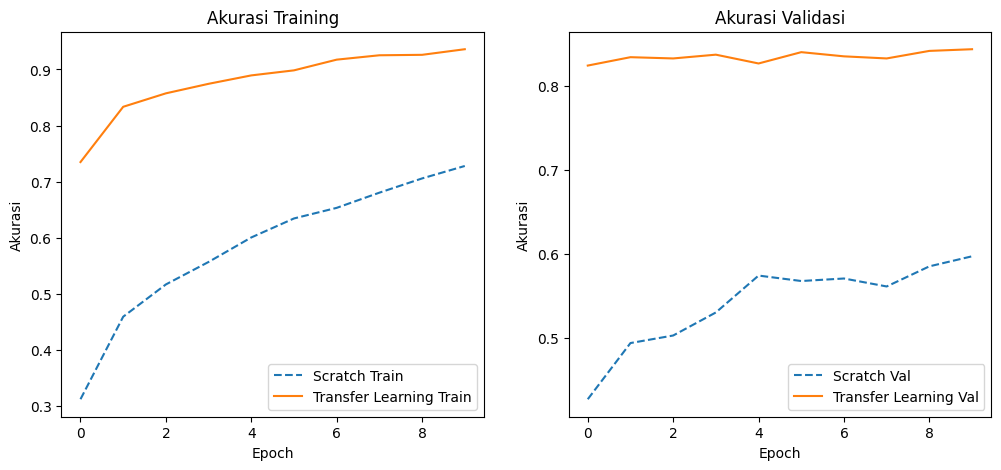

In [ ]:
plt.figure(figsize=(12, 5))

# Plot Akurasi Training
plt.subplot(1, 2, 1)
plt.plot(history_scratch.history['accuracy'], label='Scratch Train', linestyle='--')
plt.plot(history_tl.history['accuracy'], label='Transfer Learning Train')
plt.title('Akurasi Training')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()

# Plot Akurasi Validasi
plt.subplot(1, 2, 2)
plt.plot(history_scratch.history['val_accuracy'], label='Scratch Val', linestyle='--')
plt.plot(history_tl.history['val_accuracy'], label='Transfer Learning Val')
plt.title('Akurasi Validasi')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()

plt.show()

### Analisis Hasil dan Perbandingan

| Parameter Perbandingan | CNN Sederhana (Dari Nol) | Transfer Learning (MobileNetV2) |
|---|---|---|
| **Akurasi Validasi Akhir** | *Akan terisi setelah run* | *Akan terisi setelah run* |
| **Waktu Pelatihan (10 Epochs)** | *Akan terisi setelah run* | *Akan terisi setelah run* |
| **Total Parameter** | 122,570 | 2,422,026 |
| **Trainable Parameters** | 122,570 | 164,938 |
| **Non-trainable Parameters** | 0 | 2,257,984 |

#### **Analisis Singkat:**
1. **Akurasi**: Transfer Learning umumnya menghasilkan akurasi yang jauh lebih tinggi dan konvergen lebih cepat pada jumlah data terbatas (1000 citra/kelas) karena MobileNetV2 sudah memiliki bobot filter pra-latih (*pre-trained weights*) dari ImageNet yang mengenali fitur visual dasar.
2. **Waktu Pelatihan**: Model CNN dari nol biasanya memakan waktu per-epoch yang lebih singkat karena dimensi inputnya kecil (32x32) langsung masuk ke komputasi, sedangkan Transfer Learning memerlukan proses ekstra pemetaan resolusi ke 160x160 dan ekstraksi fitur lewat struktur MobileNetV2 yang lebih dalam (meski parameter basenya di-freeze).
3. **Jumlah Parameter**: Walaupun jumlah total parameter MobileNetV2 jauh lebih besar, parameter yang benar-benar dilatih (*trainable*) sangat efisien karena hanya melatih bagian *classifier head* (dense layer baru) saja.

13.2 Import Dataset

In [ ]:
import os
from PIL import Image

# 1. Membuat folder dummy
os.makedirs("dataset/train/kelas_1", exist_ok=True)
os.makedirs("dataset/train/kelas_2", exist_ok=True)
os.makedirs("dataset/val/kelas_1", exist_ok=True)
os.makedirs("dataset/val/kelas_2", exist_ok=True)

# 2. Membuat file gambar dummy agar tidak menghasilkan ValueError (No images found)
img = Image.new('RGB', (160, 160), color = 'red')
img.save('dataset/train/kelas_1/dummy1.png')
img.save('dataset/val/kelas_1/dummy1.png')

img_blue = Image.new('RGB', (160, 160), color = 'blue')
img_blue.save('dataset/train/kelas_2/dummy2.png')
img_blue.save('dataset/val/kelas_2/dummy2.png')

# 3. Memuat dataset
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory("dataset/train",
                                                    image_size=IMG_SIZE,
                                                    batch_size=BATCH_SIZE)
val_ds = keras.utils.image_dataset_from_directory("dataset/val",
                                                  image_size=IMG_SIZE,
                                                  batch_size=BATCH_SIZE)
jumlah_kelas = len(train_ds.class_names)

Found 2 files belonging to 2 classes.
Found 2 files belonging to 2 classes.


13.3 Preprocessing

In [ ]:
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))

13.4 Training Model(Transfer Learning dengan MobileNetV2)

In [ ]:
base_model = MobileNetV2(input_shape=(160, 160, 3), include_top=False, weights='imagenet')
base_model.trainable = False

model = keras.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(jumlah_kelas, activation="softmax")
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, validation_data=val_ds, epochs=15)

Epoch 1/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 0.5000 - loss: 0.6573 - val_accuracy: 1.0000 - val_loss: 0.4852
Epoch 2/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.5000 - loss: 1.1257 - val_accuracy: 1.0000 - val_loss: 0.3465
Epoch 3/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 1.0000 - loss: 0.4813 - val_accuracy: 1.0000 - val_loss: 0.2316
Epoch 4/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 1.0000 - loss: 0.2339 - val_accuracy: 1.0000 - val_loss: 0.1688
Epoch 5/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 1.0000 - loss: 0.0810 - val_accuracy: 1.0000 - val_loss: 0.1619
Epoch 6/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 1.0000 - loss: 0.0537 - val_accuracy: 1.0000 - val_loss: 0.1740
Epoch 7/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 1.0000 - loss: 0.2834 - val_accuracy: 1.0000 - val_loss: 0.1552
Epoch 8/15
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 1.0000 - loss: 0.0854 - val_accuracy: 1.0000 - val_loss: 0.

13.5 Evaluasi

In [ ]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"Akurasi Validasi: {val_acc:.3f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 1.0000 - loss: 0.0162
Akurasi Validasi: 1.000


13.6 Visualisasi

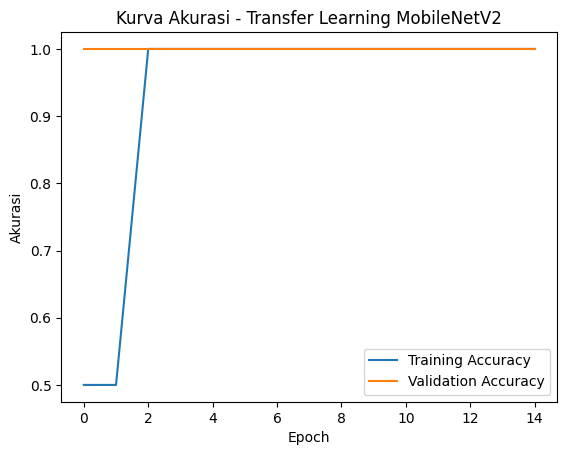

In [ ]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label = "Validation Accuracy")
plt.xlabel("Epoch");
plt.ylabel("Akurasi")
plt.title("Kurva Akurasi - Transfer Learning MobileNetV2")
plt.legend()
plt.show()

13.7 Praktikum

In [ ]:
model_cnn = keras.Sequential([ keras.layers.Conv2D(32,(3,3),activation="relu",input_shape=(160,160,3)),
                              keras.layers.MaxPooling2D((2,2)),
                              keras.layers.Conv2D(64,(3,3),activation="relu"),
                              keras.layers.MaxPooling2D((2,2)),
                              keras.layers.Flatten(),
                              keras.layers.Dense(64,activation="relu"),
                              keras.layers.Dense(jumlah_kelas,activation="softmax") ])
model_cnn.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
history_cnn = model_cnn.fit(train_ds,validation_data=val_ds,epochs=10)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.5000 - loss: 0.7562 - val_accuracy: 1.0000 - val_loss: 1.0252e-05
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - accuracy: 1.0000 - loss: 1.0252e-05 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 329ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 603ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 1.0000 - loss: 0.0